

####################################
SENTENCE: The boy plays cricket.
####################################

========== POS TAGGING ==========
WORD            POS             DESCRIPTION
-------------------------------------------------------
The             DET             determiner
boy             NOUN            noun
plays           VERB            verb
cricket         NOUN            noun
.               PUNCT           punctuation

DEPENDENCY ANALYSIS 
WORD            HEAD            DEPENDENCY
--------------------------------------------------
The             boy             det
boy             plays           nsubj
plays           plays           ROOT
cricket         plays           dobj
.               plays           punct


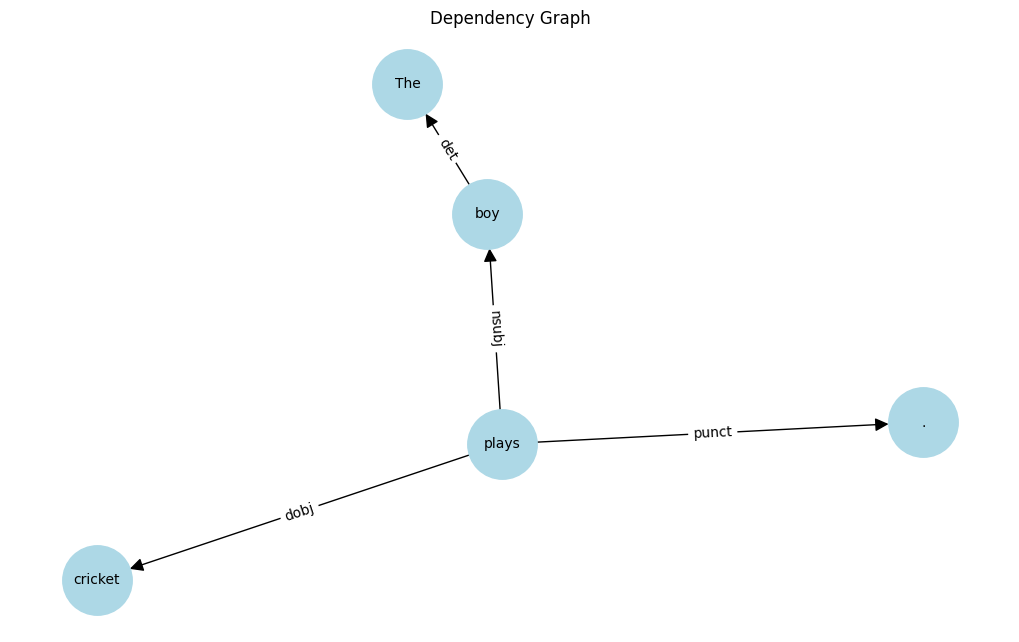


========== PHRASE STRUCTURE TREE ==========
No parse tree found.
Sentence does not match the defined CFG grammar.


####################################
SENTENCE: The girl reads book.
####################################

========== POS TAGGING ==========
WORD            POS             DESCRIPTION
-------------------------------------------------------
The             DET             determiner
girl            NOUN            noun
reads           VERB            verb
book            NOUN            noun
.               PUNCT           punctuation

DEPENDENCY ANALYSIS 
WORD            HEAD            DEPENDENCY
--------------------------------------------------
The             girl            det
girl            reads           nsubj
reads           reads           ROOT
book            reads           dobj
.               reads           punct


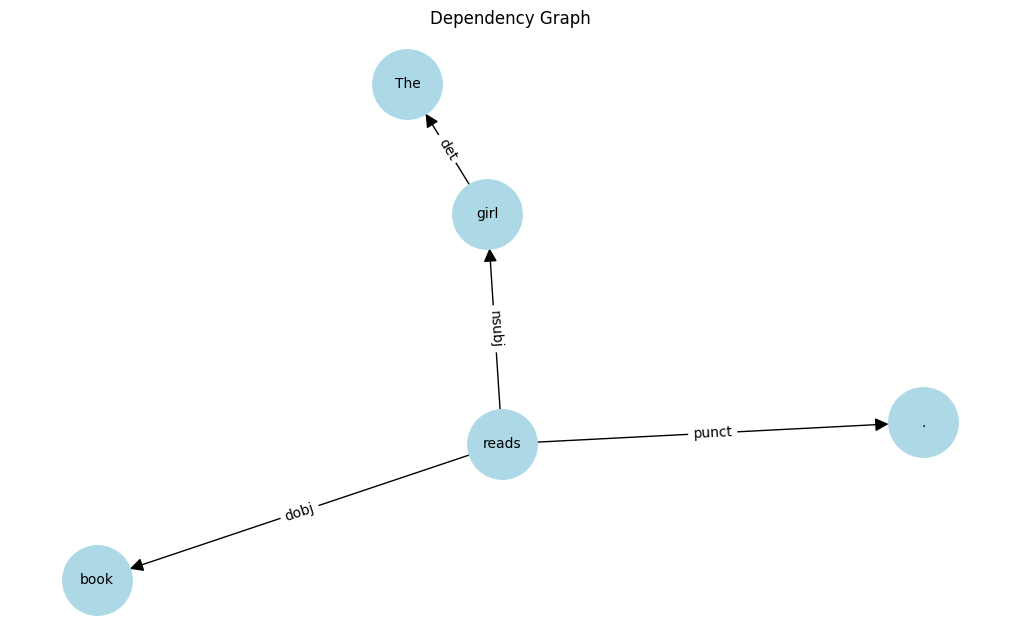


========== PHRASE STRUCTURE TREE ==========
No parse tree found.
Sentence does not match the defined CFG grammar.


####################################
SENTENCE: The intelligent student studies book.
####################################

========== POS TAGGING ==========
WORD            POS             DESCRIPTION
-------------------------------------------------------
The             DET             determiner
intelligent     ADJ             adjective
student         NOUN            noun
studies         NOUN            noun
book            NOUN            noun
.               PUNCT           punctuation

DEPENDENCY ANALYSIS 
WORD            HEAD            DEPENDENCY
--------------------------------------------------
The             book            det
intelligent     book            amod
student         studies         compound
studies         book            compound
book            book            ROOT
.               book            punct


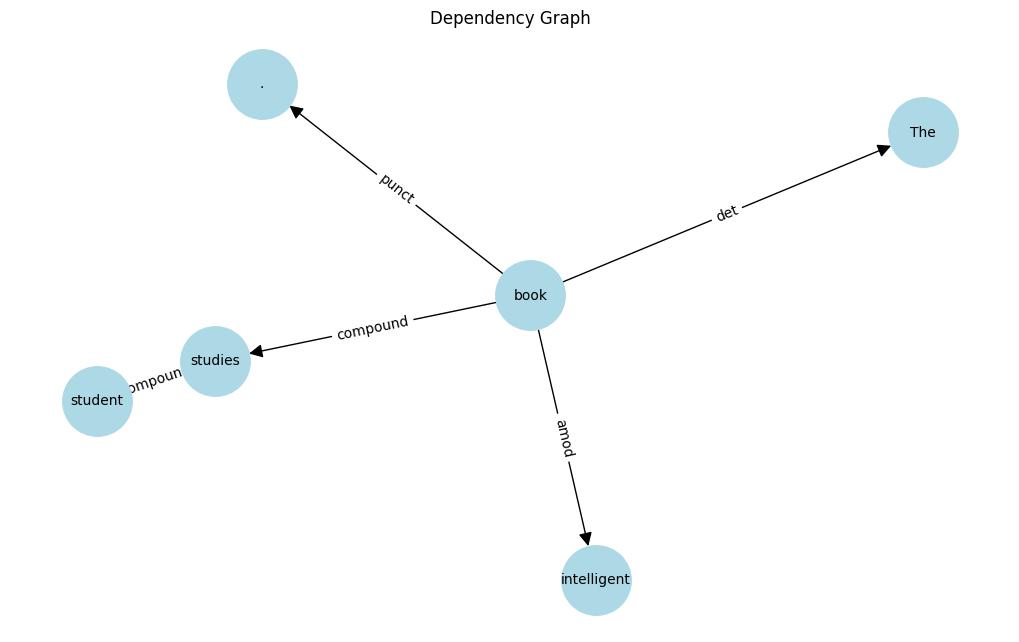


========== PHRASE STRUCTURE TREE ==========
No parse tree found.
Sentence does not match the defined CFG grammar.


####################################
SENTENCE: He plays cricket.
####################################

========== POS TAGGING ==========
WORD            POS             DESCRIPTION
-------------------------------------------------------
He              PRON            pronoun
plays           VERB            verb
cricket         NOUN            noun
.               PUNCT           punctuation

DEPENDENCY ANALYSIS 
WORD            HEAD            DEPENDENCY
--------------------------------------------------
He              plays           nsubj
plays           plays           ROOT
cricket         plays           dobj
.               plays           punct


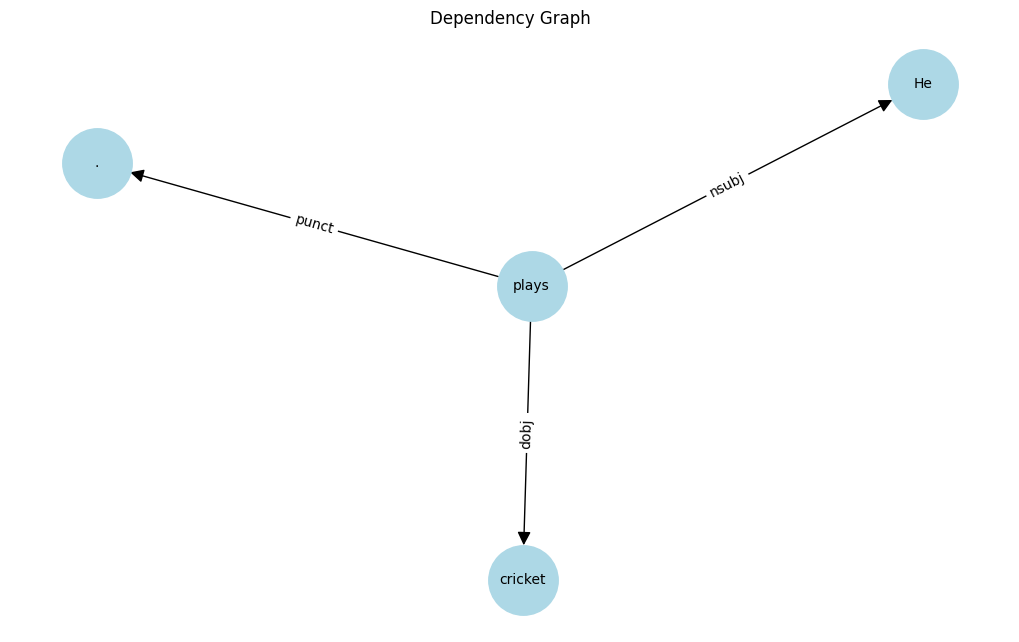


========== PHRASE STRUCTURE TREE ==========
No parse tree found.
Sentence does not match the defined CFG grammar.

All NLP tasks completed successfully!


In [ ]:
import spacy
import nltk
import networkx as nx
import matplotlib.pyplot as plt

from nltk import CFG
from nltk.parse import ChartParser


nlp = spacy.load("en_core_web_sm")


def pos_tagging(sentence):

    doc = nlp(sentence)

    print("\n========== POS TAGGING ==========")

    print(f"{'WORD':15} {'POS':15} {'DESCRIPTION'}")
    print("-" * 55)

    for token in doc:

        print(
            f"{token.text:15} "
            f"{token.pos_:15} "
            f"{spacy.explain(token.pos_)}"
        )


def dependency_graph(sentence):

    doc = nlp(sentence)

    G = nx.DiGraph()

    print("\nDEPENDENCY ANALYSIS ")

    print(f"{'WORD':15} {'HEAD':15} {'DEPENDENCY'}")
    print("-" * 50)

    for token in doc:

        print(
            f"{token.text:15} "
            f"{token.head.text:15} "
            f"{token.dep_}"
        )

        G.add_node(token.i, label=token.text)

        if token.head != token:

            G.add_edge(
                token.head.i,
                token.i,
                label=token.dep_
            )

    pos = nx.spring_layout(G, seed=42)

    labels = nx.get_node_attributes(G, 'label')

    edge_labels = nx.get_edge_attributes(G, 'label')

    plt.figure(figsize=(10, 6))

    nx.draw(
        G,
        pos,
        labels=labels,
        with_labels=True,
        node_size=2500,
        node_color="lightblue",
        font_size=10,
        arrows=True,
        arrowsize=20
    )

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels
    )

    plt.title("Dependency Graph")

    plt.axis("off")

    plt.show()



def phrase_structure_tree(sentence):

    print("\n========== PHRASE STRUCTURE TREE ==========")

    # Define grammar
    grammar = CFG.fromstring("""

    S -> NP VP

    NP -> DT NN | PRP | JJ NN

    VP -> VBZ NP | VBP NP | VBZ | VBP

    DT -> 'The' | 'the' | 'A' | 'a'

    NN -> 'boy' | 'girl' | 'cricket' | 'book' | 'student'

    PRP -> 'He' | 'She' | 'I'

    JJ -> 'good' | 'intelligent'

    VBZ -> 'plays' | 'reads' | 'studies'

    VBP -> 'play' | 'read' | 'study'

    """)

    # Create parser
    parser = ChartParser(grammar)

    # Tokenize sentence
    words = sentence.replace(".", "").split()

    # Generate parse trees
    trees = list(parser.parse(words))

    if trees:

        for tree in trees:

            print(tree)

            # Display tree
            tree.pretty_print()

            tree.draw()

    else:

        print("No parse tree found.")
        print("Sentence does not match the defined CFG grammar.")


sentences = [

    "The boy plays cricket.",

    "The girl reads book.",

    "The intelligent student studies book.",

    "He plays cricket."

]


for sentence in sentences:

    print("\n\n####################################")
    print("SENTENCE:", sentence)
    print("####################################")

    # POS Tagging
    pos_tagging(sentence)

    # Dependency Graph
    dependency_graph(sentence)

    # Phrase Structure Tree
    phrase_structure_tree(sentence)


print("\nAll NLP tasks completed successfully!")